In [1]:
from os.path import basename, exists


def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + local)


download("https://github.com/AllenDowney/ThinkStats/raw/v3/nb/thinkstats.py")

In [2]:
try:
    import empiricaldist
except ImportError:
    %pip install empiricaldist

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thinkstats import decorate

In [4]:
from empiricaldist import FreqTab
ftab = FreqTab.from_seq([1,2,2,3,5])
ftab

,freqs
1,1
2,2
3,1
5,1


In [5]:
n = ftab.sum()
n

np.int64(5)

In [6]:
pmf = ftab/n
pmf

,probs
1,0.2
2,0.4
3,0.2
5,0.2


In [7]:
pmf.sum()

np.float64(1.0)

In [8]:
from empiricaldist import Pmf

pmf = Pmf.from_seq([1,2,2,3,5])
pmf

,probs
1,0.2
2,0.4
3,0.2
5,0.2


In [9]:
pmf.sum()

np.float64(1.0)

In [10]:
pmf[2]

np.float64(0.4)

In [11]:
pmf(2)

np.float64(0.4)

In [12]:
pmf[2] = 0.2
pmf(2)

np.float64(0.2)

In [13]:
pmf[2] += 0.3
pmf[2]

np.float64(0.5)

In [14]:
pmf[2] *=0.5
pmf[2]

np.float64(0.25)

In [15]:
pmf.sum()

np.float64(0.8500000000000001)

In [16]:
pmf.normalize()

np.float64(0.8500000000000001)

In [17]:
pmf.copy()

,probs
1,0.235294
2,0.294118
3,0.235294
5,0.235294


In [18]:
seq = [1, 2, 2, 3, 5]

n = len(seq)
mean = np.sum(seq) / n
mean

np.float64(2.6)

In [19]:
pmf = Pmf.from_seq(seq)

In [20]:
mean = np.sum(pmf.ps * pmf.qs)
mean

np.float64(2.6)

In [21]:
pmf.mean()

np.float64(2.6)

In [22]:
deviations = pmf.qs - mean

In [23]:
var = np.sum(pmf.ps * deviations**2)
var

np.float64(1.84)

In [24]:
pmf.var()

np.float64(1.84)

In [25]:
np.sqrt(var)

np.float64(1.3564659966250536)

In [26]:
pmf.std()

np.float64(1.3564659966250536)

In [27]:
pmf.mode()

np.int64(2)

In [28]:
ranges = pd.interval_range(start = 5, end = 50, freq = 5, closed = 'left')
ranges.name = 'class size'

data = pd.DataFrame(index=ranges)
data['count'] = [8,8,14,4,6,12,8,3,2]
data

,count
class size,
"[5, 10)",8
"[10, 15)",8
"[15, 20)",14
"[20, 25)",4
"[25, 30)",6
"[30, 35)",12
"[35, 40)",8
"[40, 45)",3
"[45, 50)",2


In [29]:
sizes = ranges.left + 2
sizes

Index([7, 12, 17, 22, 27, 32, 37, 42, 47], dtype='int64')

In [30]:
counts = data['count']
actual_pmf = Pmf(counts, sizes, name = 'actual')
actual_pmf.normalize()

np.int64(65)

In [31]:
actual_pmf.mean()

np.float64(23.692307692307693)

In [32]:
def bias(pmf, name):
    #multiply each probability by class size
    ps = pmf.ps * pmf.qs

    #mane a new PMF and normalize it
    new_pmf = Pmf(ps, pmf.qs, name=name)
    new_pmf.normalize()
    return new_pmf

In [33]:
observed_pmf = bias(actual_pmf, name = 'observed')

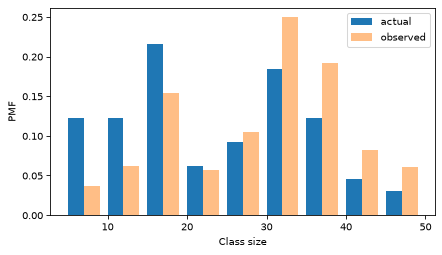

In [34]:
from thinkstats import two_bar_plots

two_bar_plots(actual_pmf, observed_pmf, width=2)
decorate(xlabel='Class size', ylabel = 'PMF')

In [35]:
observed_pmf.mean()

np.float64(29.123376623376622)

In [36]:
def unbias(pmf, name):
    #divide each probability by class size
    ps = pmf.ps / pmf.qs

    new_pmf = Pmf(ps, pmf.qs, name=name)
    new_pmf.normalize()
    return new_pmf

In [37]:
debiased_pmf = unbias(observed_pmf, "debiased")
debiased_pmf.mean()

np.float64(23.692307692307693)